In [1]:
import os
import sys

In [13]:
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.pyplot as plt
#import cv2
import cv2 as cv

In [3]:
dir_paht = '../../learning/segment_anything/Wide Field Images Cropped/'
sys.path.append(dir_paht)

In [4]:
images = [cv.imread(os.path.join(dir_paht, x)) if x[-3:] == 'jpg' else None 
          for x in os.listdir(dir_paht)]
images = [cv.cvtColor(image, cv.COLOR_BGR2RGB) for image in images]

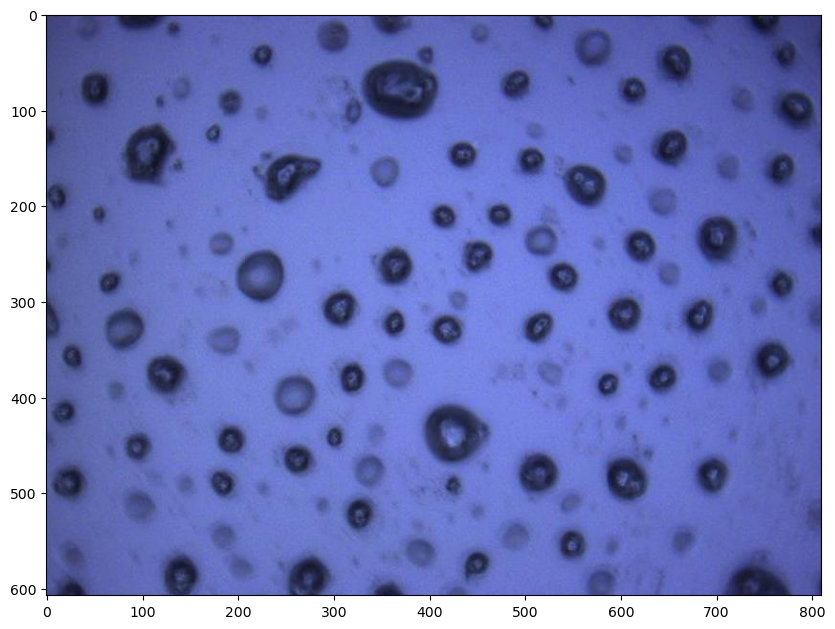

In [7]:
image = images[0]
plt.figure(figsize=(10,10))
plt.imshow(image)

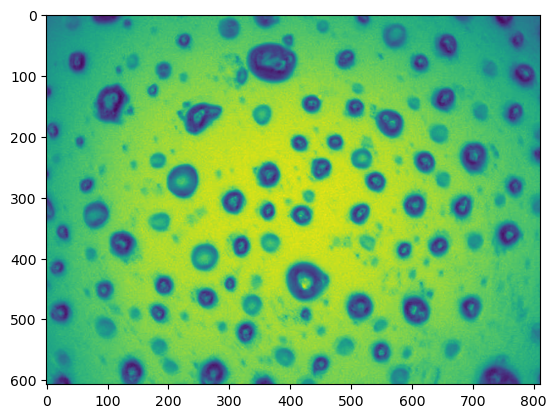

In [8]:
grayscale = cv.cvtColor(image, cv.COLOR_BGR2GRAY)
plt.imshow(grayscale)

(array([  1677.,  11206.,  19263.,  17168.,  21791.,  42290.,  91912.,
        126312., 125248.,  34803.]),
 array([ 21. ,  36.2,  51.4,  66.6,  81.8,  97. , 112.2, 127.4, 142.6,
        157.8, 173. ]),
 <BarContainer object of 10 artists>)

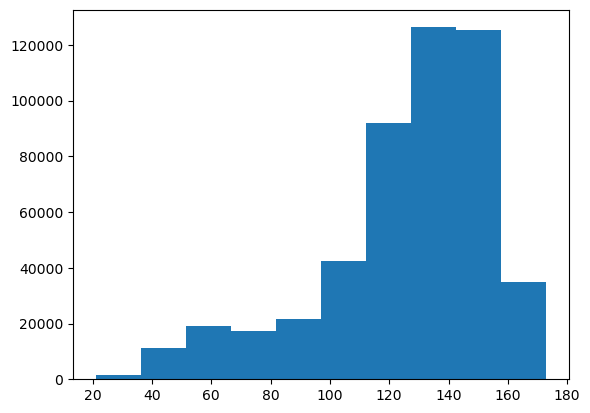

In [9]:
plt.hist(grayscale.flatten())

In [57]:
low = np.array([0])
high = np.array([90])

gray = cv.cvtColor(image, cv.COLOR_BGR2GRAY)

ret, thresh = cv.threshold(gray,0,255, 9)#,cv.THRESH_BINARY_INV+cv.THRESH_OTSU)
thresh = cv.inRange(grayscale, low, high)

# noise removal
kernel = np.ones((3,3),np.uint8)
opening = cv.morphologyEx(thresh,cv.MORPH_OPEN,kernel, iterations = 2)
# sure background area
sure_bg = cv.dilate(opening,kernel,iterations=3)
# Finding sure foreground area
dist_transform = cv.distanceTransform(opening,cv.DIST_L2,5)
ret, sure_fg = cv.threshold(dist_transform,0.7*dist_transform.max(),255,0)
# Finding unknown region
sure_fg = np.uint8(sure_fg)
unknown = cv.subtract(sure_bg,sure_fg)

dist_transform = cv.distanceTransform(opening,cv.DIST_L2,5)
ret, sure_fg = cv.threshold(dist_transform,0.01*dist_transform.max(),255,0)

mask = (sure_fg==255)

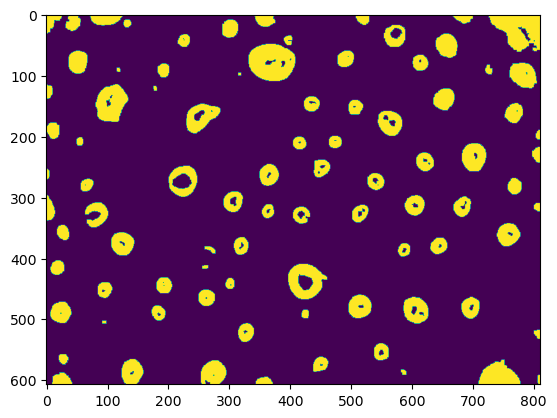

In [58]:
plt.imshow(mask)